# Scheduler benchmark figures
Figures are also written to `figures/*.pdf`.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

import helpers as h

# schedulers shown in all figures, colored in this order (8 colors, the rest are gray)
SCHEDULERS: list[h.Scheduler] = [
    "backoff",
    "detour-lhs-400",
    "detour-rhs-400",
    "detour-min-400",
    "detour1",
    "ctxt-400",
    "size-400",
    "pat-400",
    "detour-classbased-400",
    "detour-rhs-400-classboost",
    "detour-rhs-400-classboost-halfed",
    # "backoff-fresh",
    # "backoff-illegal",
    # "backoff-legal",
    # "detour-classbased-1000",
    # "detour-classbased-500",
    # "detour-lhs-400-dynamic",
    # "detour-lhs-400-prestart",
    # "detour-lhs-400-shortcut-simple",
    # "detour-lhs-400-shortcut",
    # "detour-lhs-400-simple",
    # "detour-lhs-400-simple2",
    # "detour-lhs-400-simple3",
    # "detour-lhs-400-simple4-800",
    # "detour-lhs-400-simple4-nostorage",
    # "detour-lhs-400-simple4-shortcut",
    # "detour-lhs-400-simple4",
    # "detour-lhs-400_800-shortcut",
    # "detour-rhs-100",
    # "detour-rhs-20",
    # "detour-rhs-200",
    # "detour-rhs-300",
    # "detour-rhs-400-boost",
    # "detour-rhs-400-boost2",
    # "detour-rhs-400-merge",
    # "detour-rhs-500",
    # "detour-rhs",
    # "detour-vanilla",
    # "detour1-400",
    # "detour1-rhs",
    # "size-bounded",
]

h.setup_style()
h.select(SCHEDULERS)
df = h.load().filter(pl.col("scheduler").is_in(SCHEDULERS))
fin = h.finals(df)
h.check_runs(fin)
CASES = sorted(fin["case"].unique())
METRICS: list[h.Metric] = ["cost", *h.RESOURCES]

## Ranking
Final cost relative to the best scheduler on each run, geometric mean over runs.

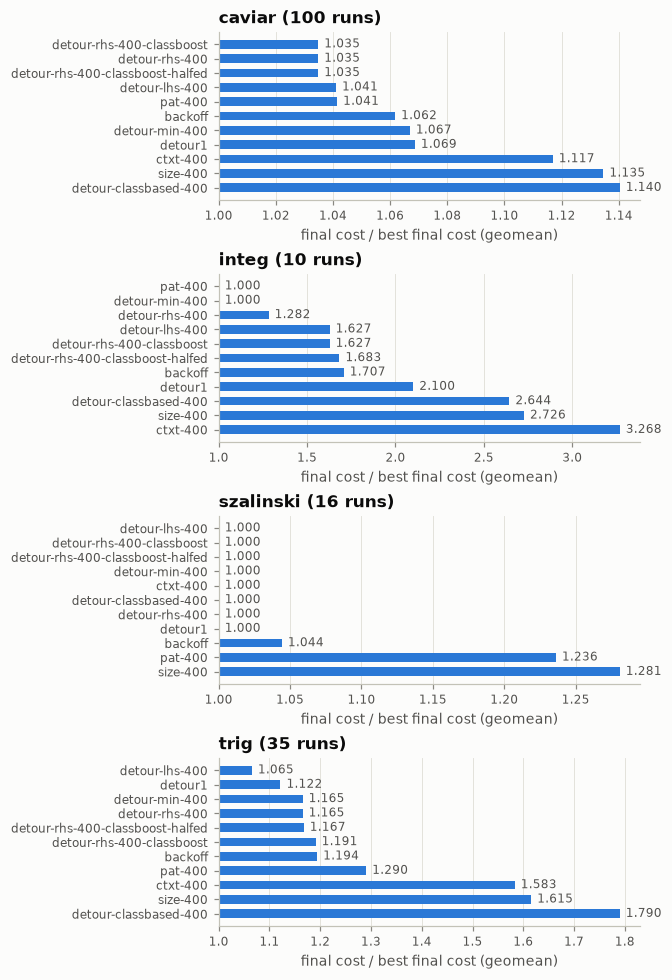

In [2]:
fig, axes = plt.subplots(
    len(CASES), 1, figsize=(6, 2.2 * len(CASES)), layout="constrained"
)
for case, ax in zip(CASES, axes):
    h.plot_ranking(fin, case, ax)
h.save(fig, "ranking")

Plain sum of the final cost / time / size over all runs, as in `dump.py`.

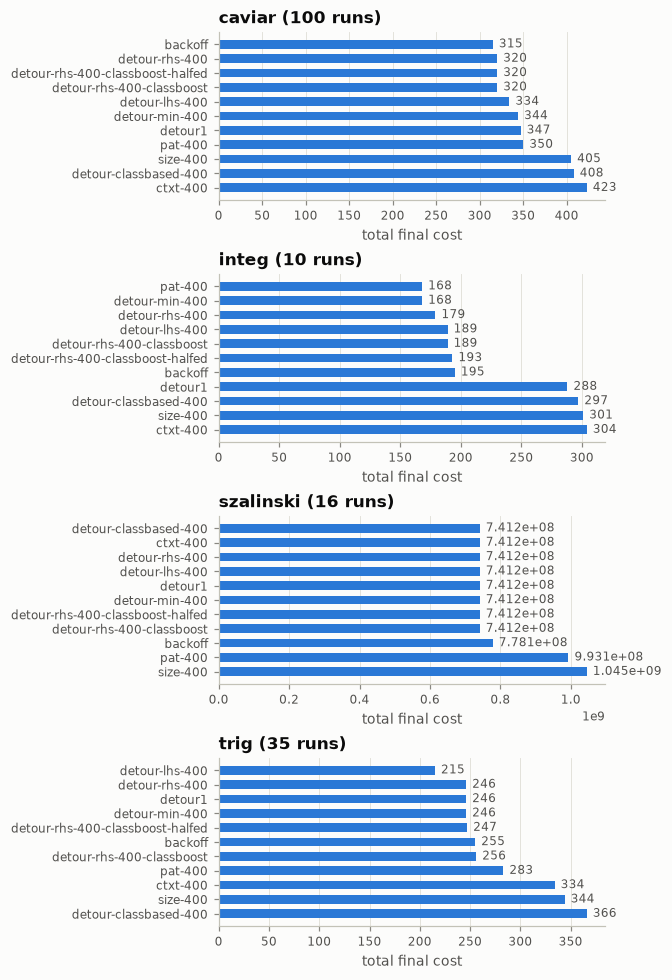

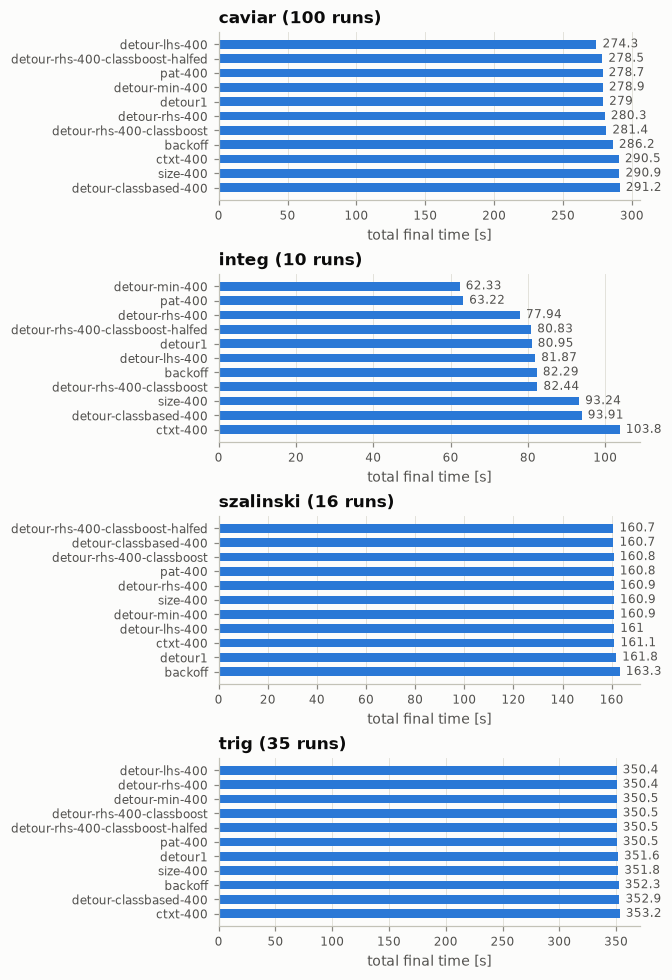

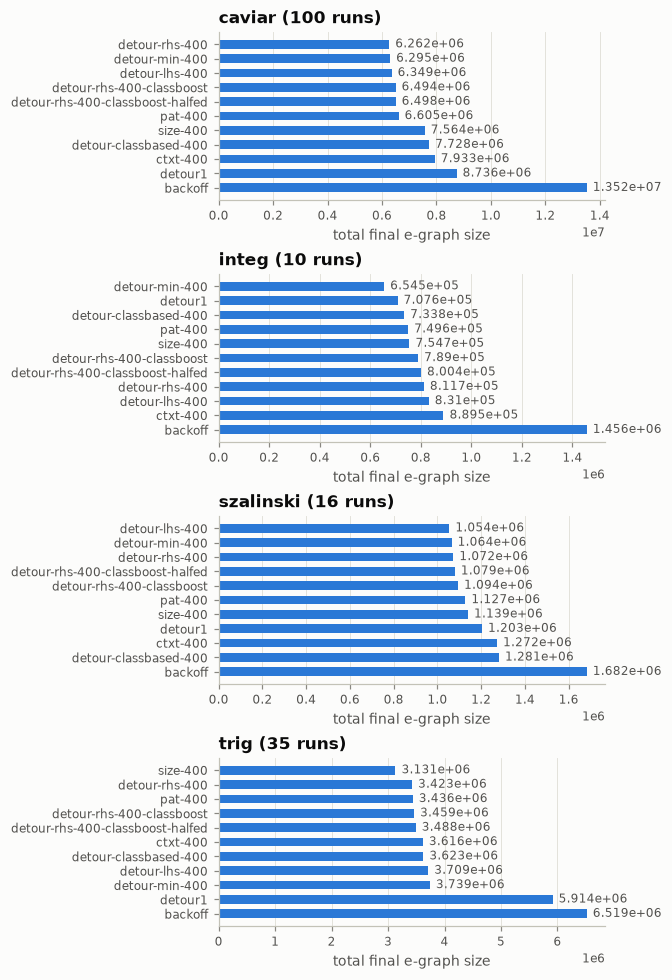

In [3]:
for metric in METRICS:
    fig, axes = plt.subplots(
        len(CASES), 1, figsize=(6, 2.2 * len(CASES)), layout="constrained"
    )
    for case, ax in zip(CASES, axes):
        h.plot_sum_ranking(fin, case, ax, metric=metric)
    h.save(fig, f"sum-{metric}")

## Pairwise wins

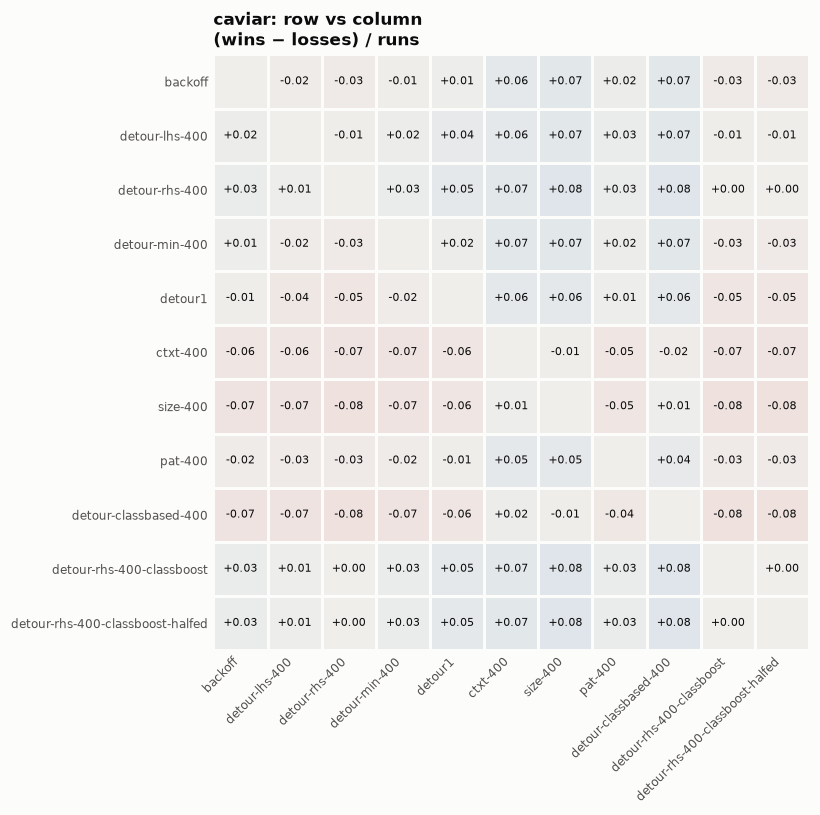

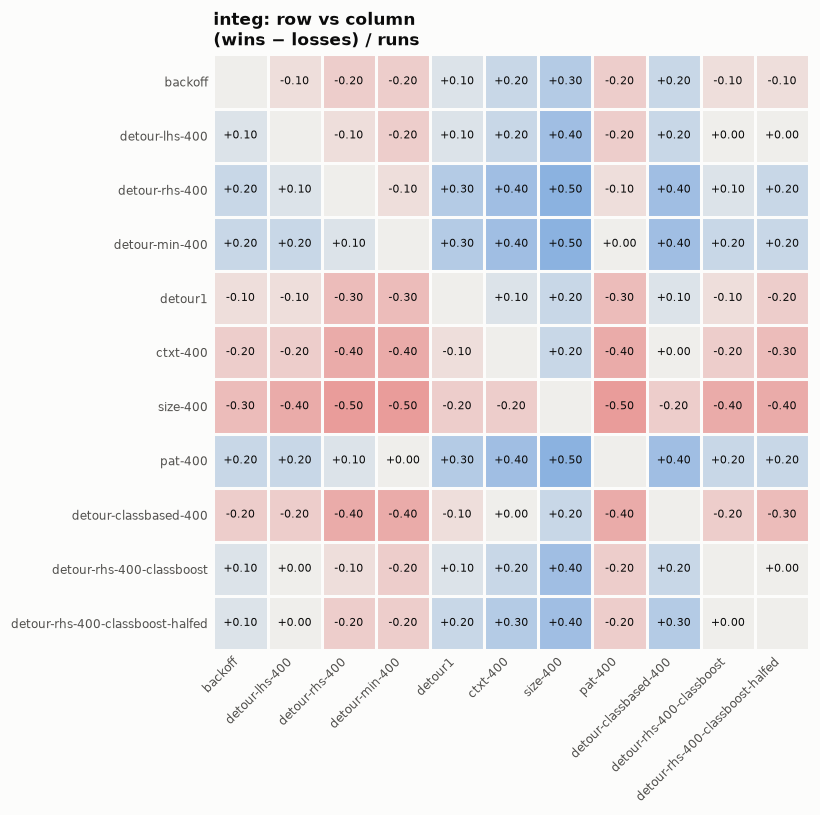

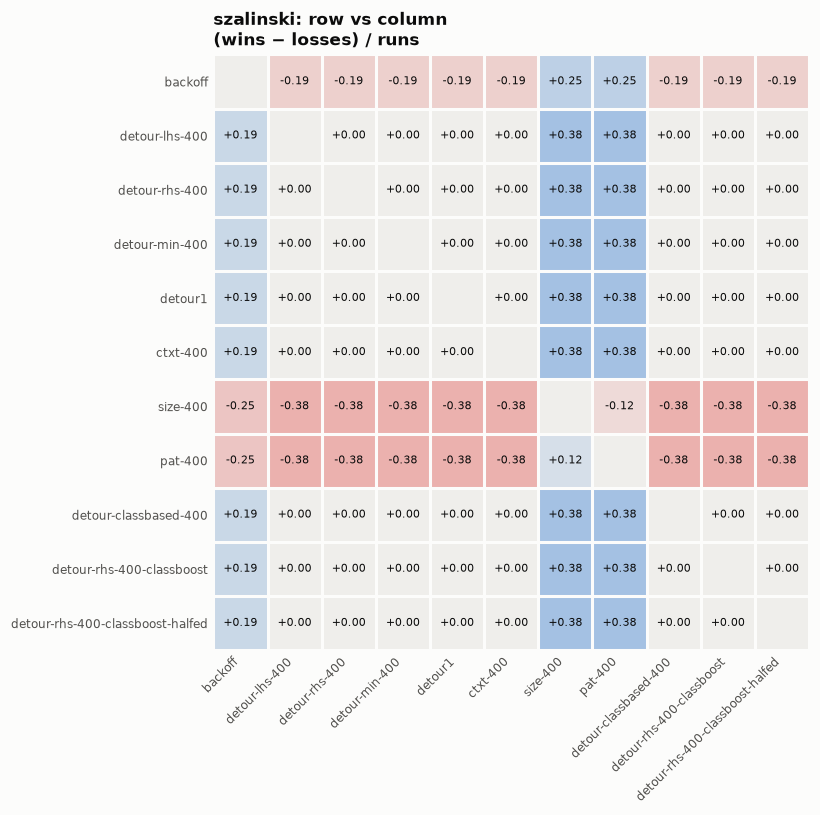

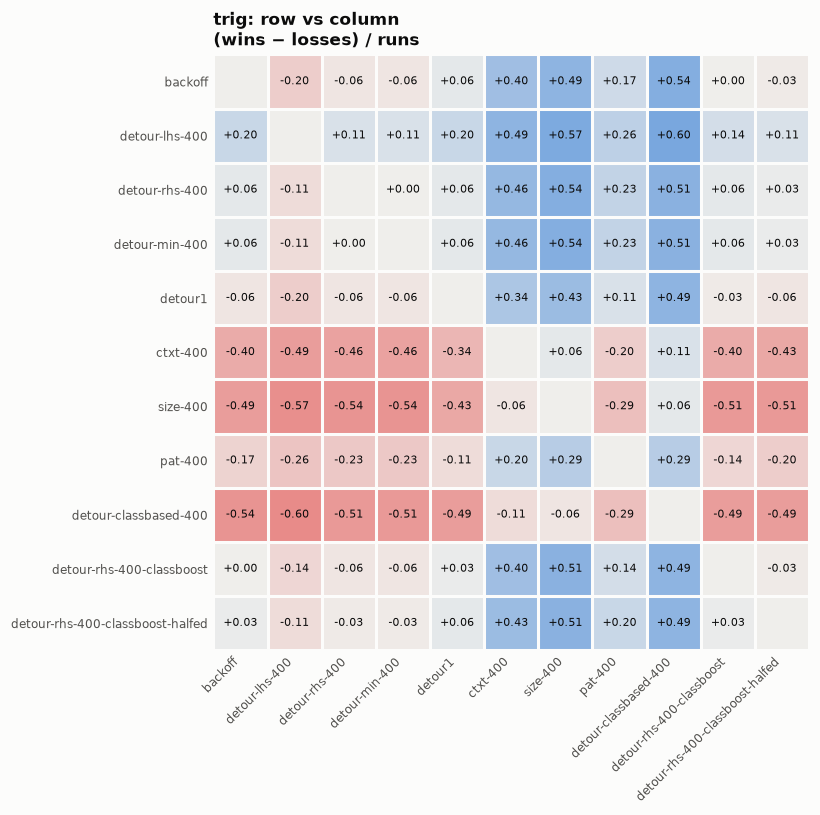

In [4]:
for case in CASES:
    n = fin.filter(pl.col("case") == case)["scheduler"].n_unique()
    fig, ax = plt.subplots(figsize=(2.5 + 0.6 * n, 1.8 + 0.5 * n), layout="constrained")
    h.plot_wins(fin, case, ax)
    h.save(fig, f"wins-{case}")

## Quality over resources
Fraction of runs at the best known cost after a given time / e-graph size.

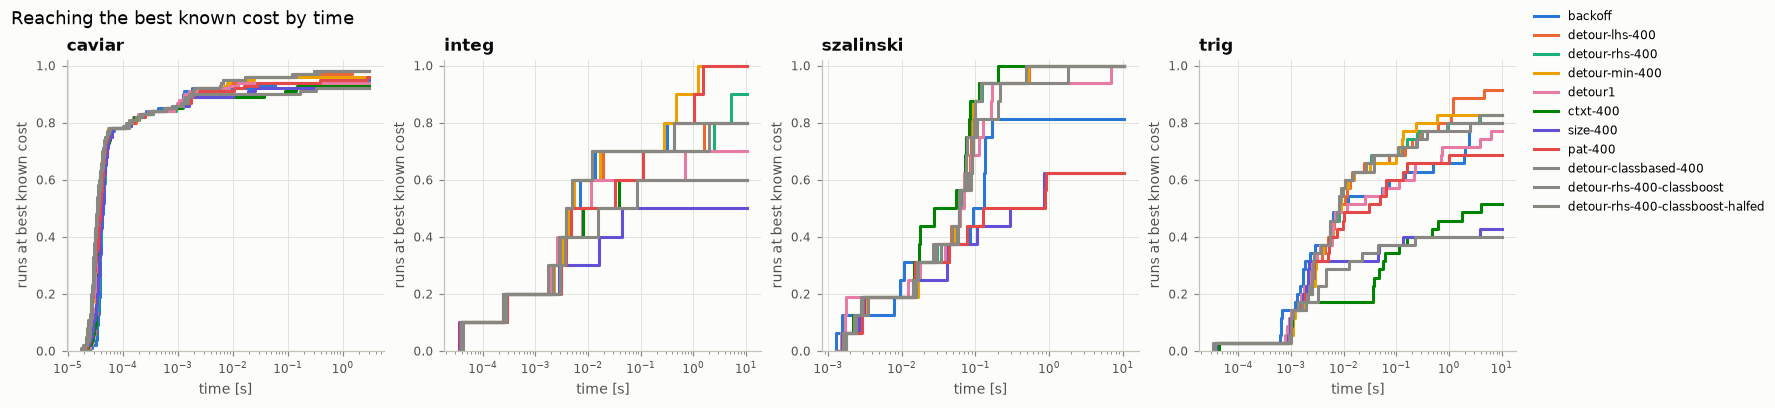

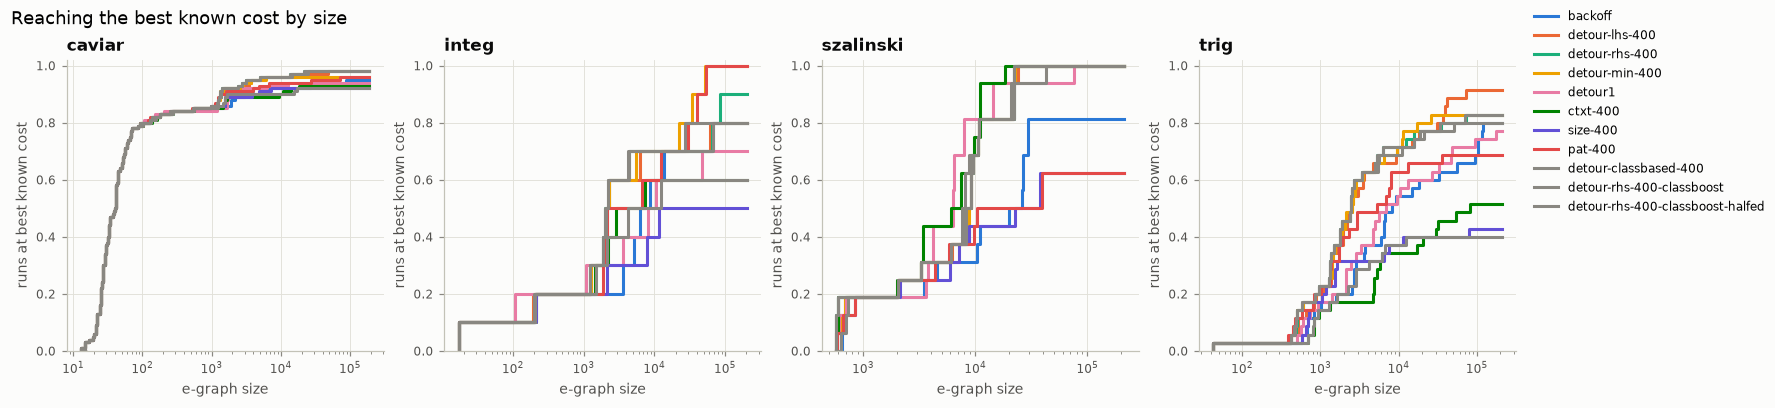

In [5]:
for res in h.RESOURCES:
    fig, axes = plt.subplots(
        1, len(CASES), figsize=(4 * len(CASES), 3.6), layout="constrained"
    )
    for case, ax in zip(CASES, axes):
        h.plot_profile(fin, case, res, ax)
    fig.suptitle(f"Reaching the best known cost by {res}", x=0, ha="left")
    h.legend(fig)
    h.save(fig, f"profile-{res}")

Single runs, cut off when the best cost is reached (★).

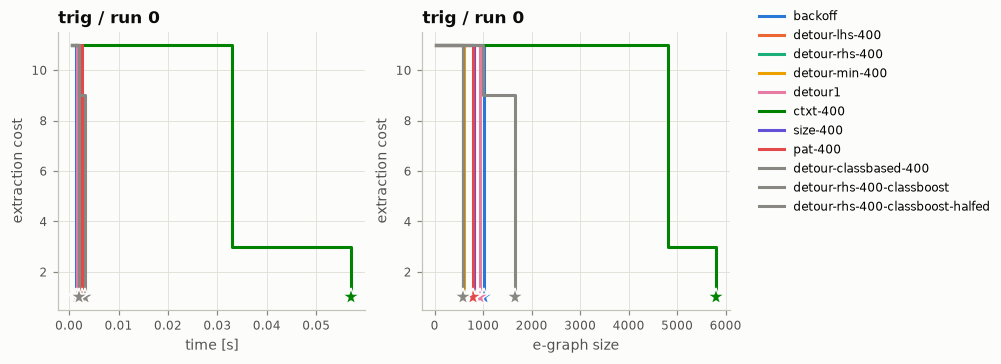

In [6]:
case, run = "trig", 0
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
for res, ax in zip(h.RESOURCES, axes):
    h.plot_quality(df, case, run, res, ax)
h.legend(fig)
h.save(fig, f"quality-{case}-{run}")

Development per iteration for the same run.

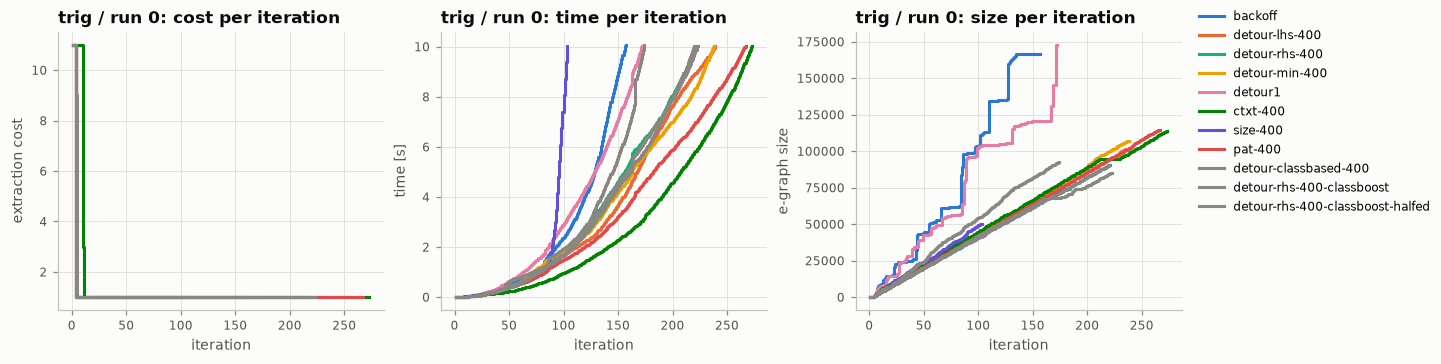

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), layout="constrained")
for metric, ax in zip(METRICS, axes):
    h.plot_dev(df, case, run, ax, metric=metric)
h.legend(fig)
h.save(fig, f"dev-{case}-{run}")

## Caviar

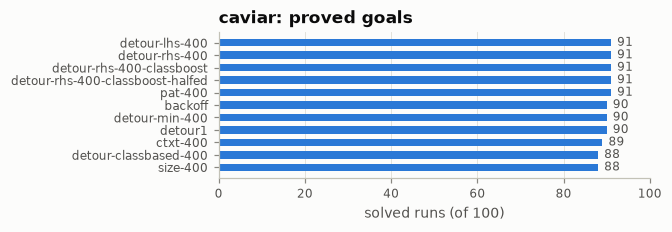

In [8]:
fig, ax = plt.subplots(figsize=(6, 2), layout="constrained")
h.plot_solved(fin, ax, "caviar")
h.save(fig, "caviar-solved")